# Import Data

In [2]:
# Import Library
import pandas as pd
import numpy as np
from scipy.stats import zscore
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
## Import Excel
df = pd.read_excel("Amazon.xlsx")

df

,Order ID,Order Date,Ship Date,EmailID,Geography,Category,Product Name,Sales,Quantity,Profit
0,CA-2013-138688,2013-06-13,2013-06-17,DarrinVanHuff@gmail.com,"United States,Los Angeles,California",Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,2,6.8714
1,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.860,7,14.1694
2,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Art,Newell 322,7.280,4,1.9656
3,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Phones,Mitel 5320 IP Phone VoIP phone,907.152,4,90.7152
4,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Binders,DXL Angle-View Binders with Locking Rings by S...,18.504,3,5.7825
...,...,...,...,...,...,...,...,...,...,...
3198,CA-2013-125794,2013-09-30,2013-10-04,MarisLaWare@gmail.com,"United States,Los Angeles,California",Accessories,Memorex Mini Travel Drive 64 GB USB 2.0 Flash ...,36.240,1,15.2208
3199,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2,15.6332
3200,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Phones,Aastra 57i VoIP phone,258.576,2,19.3932
3201,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4,13.3200


Anasisi data transaksi penjualan pada Amazon yang jenis datanya adalah Excel ini mengguanakan Python dengan bertujuan untuk Menganalisis data penjualan.

Untuk menganalisis data Amazon ini yang menggunakan Python, tidak lupa untuk mengimport berbagai libraries seperti: **panda, numpy, zscore, seaborn, matplotlib, LabelEncoder.**

# Data Exploration

## head()

In [3]:
'''
Kode head() ini digunakan untuk Menampilkan 5 baris pertama (default) dan untuk menampilkan Nama kolom apa saja yang ada
'''
# Copy data biar tidak ditiban
df_copy = df.copy()
df_copy.head()

,Order ID,Order Date,Ship Date,EmailID,Geography,Category,Product Name,Sales,Quantity,Profit
0,CA-2013-138688,2013-06-13,2013-06-17,DarrinVanHuff@gmail.com,"United States,Los Angeles,California",Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,2,6.8714
1,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.860,7,14.1694
2,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Art,Newell 322,7.280,4,1.9656
3,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Phones,Mitel 5320 IP Phone VoIP phone,907.152,4,90.7152
4,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Binders,DXL Angle-View Binders with Locking Rings by S...,18.504,3,5.7825


## info()

In [4]:
'''
Kode infp() ini digunakan untuk Menampilkan, Jumlah baris dan kolom, tipe data, dan jumlah missing value
'''
# Info data
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 3203 entries, 0 to 3202
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Order ID      3203 non-null   str           
 1   Order Date    3203 non-null   datetime64[us]
 2   Ship Date     3203 non-null   datetime64[us]
 3   EmailID       3203 non-null   str           
 4   Geography     3203 non-null   str           
 5   Category      3203 non-null   str           
 6   Product Name  3203 non-null   str           
 7   Sales         3203 non-null   float64       
 8   Quantity      3203 non-null   int64         
 9   Profit        3203 non-null   float64       
dtypes: datetime64[us](2), float64(2), int64(1), str(5)
memory usage: 605.8 KB


-------------------------
Berdasarkan hasil info() pada DataFrame df_copy, terdapat 3203 Baris dan 10 Kolom pada data tersebut. Tipe data pada setiap Kolom tidak ada yang bermasalah, dan juga tidak ada Missing Value terhadap data df_copy tersebut.

## describe()

In [5]:
'''
Kode describe() digunakan untuk Cek struktur dan data sekaligus: melihat jumlah data, jumlah rata rata, nilai max dan min, 
Kuartil 1 sampa 3 (Q1 - Q3), Standar deviasi(std).
'''
# describsi data
df_copy.describe()

,Order Date,Ship Date,Sales,Quantity,Profit
count,3203,3203,3203.000000,3203.000000,3203.000000
mean,2013-05-10 03:06:07.530440,2013-05-14 01:25:25.195129,226.493233,3.828910,33.849032
min,2011-01-07 00:00:00,2011-01-09 00:00:00,0.990000,1.000000,-3399.980000
25%,2012-05-22 00:00:00,2012-05-26 00:00:00,19.440000,2.000000,3.852000
50%,2013-07-22 00:00:00,2013-07-25 00:00:00,60.840000,3.000000,11.166400
75%,2014-05-23 00:00:00,2014-05-27 00:00:00,215.809000,5.000000,33.000400
max,2014-12-31 00:00:00,2015-01-06 00:00:00,13999.960000,14.000000,6719.980800
std,NaN,NaN,524.876877,2.260947,174.109081


Pada analisis data tersebut bisa dilihat bahwa nilai rata rata *Sales 226.49, Quantity 3.82, dan Profit 33.84,* 
Untuk nilai median (Nilai tengah) seperti *Sales 60.84, Quantity 3, dan Profit 11.16,* untuk nilai std bisa dilihat bahwa *Sales 524.87,
Quantity 2.26, dan Profit 174.10*

In [68]:
# describsi data
df_copy.describe(include="object")

C:\Users\rakad\AppData\Local\Temp\ipykernel_3136\1720003612.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_copy.describe(include="object")


,Order ID,EmailID,Geography,Category,Product Name
count,3203,3203,3203,3203,3203
unique,1611,686,170,17,1494
top,CA-2013-165330,WilliamBrown@gmail.com,"United States,Los Angeles,California",Binders,Staples
freq,11,24,747,471,60


## Kolom baru tahunan

In [7]:
df_copy['Order_Year'] = df_copy['Order Date'].dt.year
df_copy['Ship_Year']  = df_copy['Ship Date'].dt.year
df_copy

,Order ID,Order Date,Ship Date,EmailID,Geography,Category,Product Name,Sales,Quantity,Profit,Order_Year,Ship_Year
0,CA-2013-138688,2013-06-13,2013-06-17,DarrinVanHuff@gmail.com,"United States,Los Angeles,California",Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,2,6.8714,2013,2013
1,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.860,7,14.1694,2011,2011
2,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Art,Newell 322,7.280,4,1.9656,2011,2011
3,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Phones,Mitel 5320 IP Phone VoIP phone,907.152,4,90.7152,2011,2011
4,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Binders,DXL Angle-View Binders with Locking Rings by S...,18.504,3,5.7825,2011,2011
...,...,...,...,...,...,...,...,...,...,...,...,...
3198,CA-2013-125794,2013-09-30,2013-10-04,MarisLaWare@gmail.com,"United States,Los Angeles,California",Accessories,Memorex Mini Travel Drive 64 GB USB 2.0 Flash ...,36.240,1,15.2208,2013,2013
3199,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2,15.6332,2014,2014
3200,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Phones,Aastra 57i VoIP phone,258.576,2,19.3932,2014,2014
3201,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4,13.3200,2014,2014


# EDA Sebelum cleaning

## Unvariate

<Figure size 1200x800 with 0 Axes>

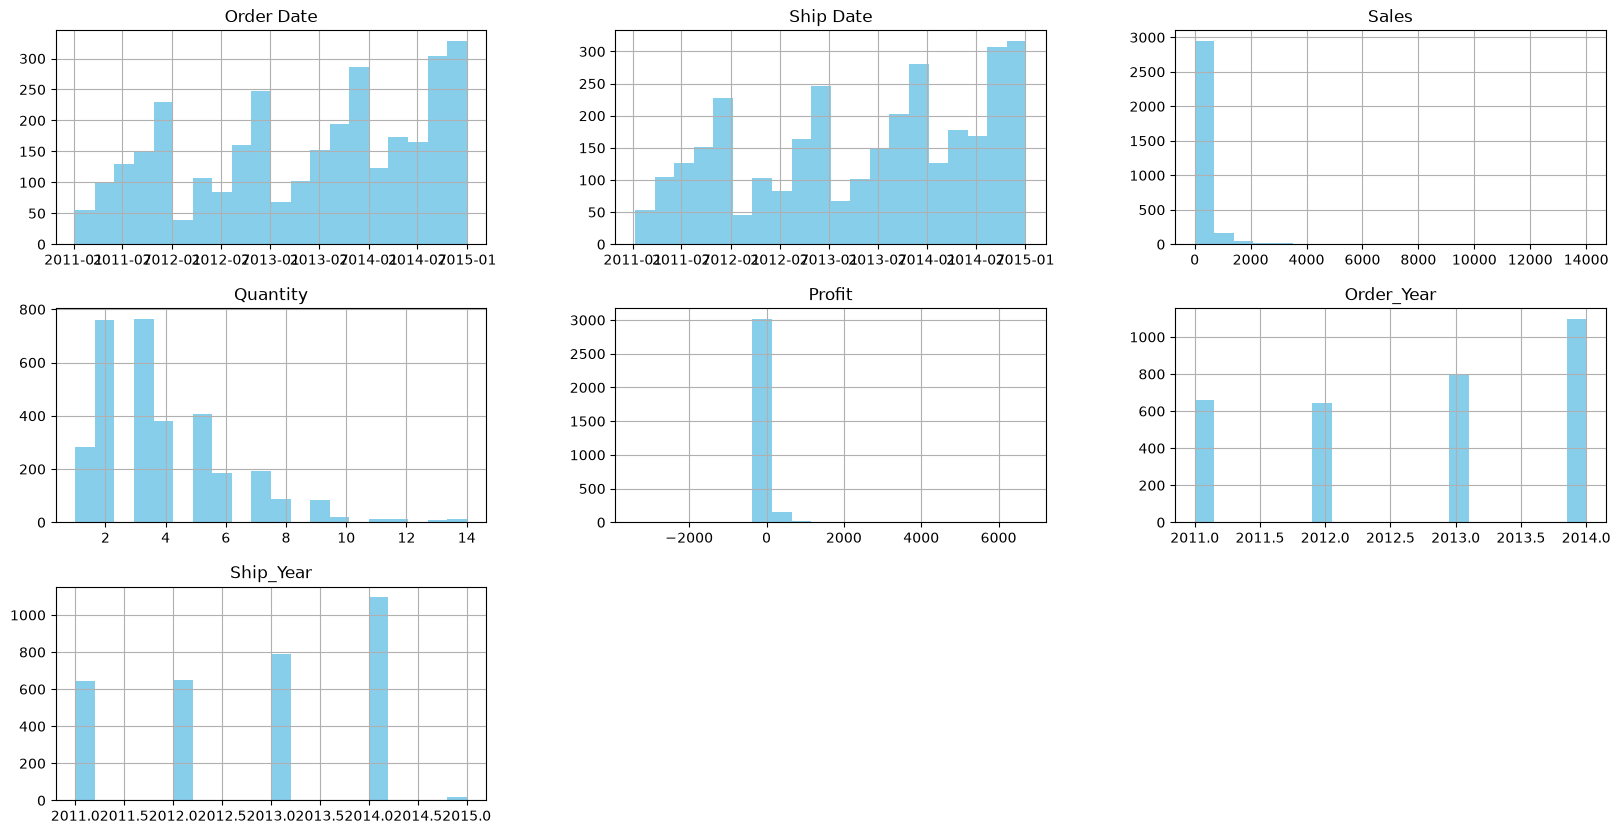

In [8]:
plt.figure(figsize=(12,8))
df_copy.hist(bins = 20, figsize = (20,10), color = "skyblue")
plt.title("Distribusi Variable Numerik")
plt.show()

## Heatmap

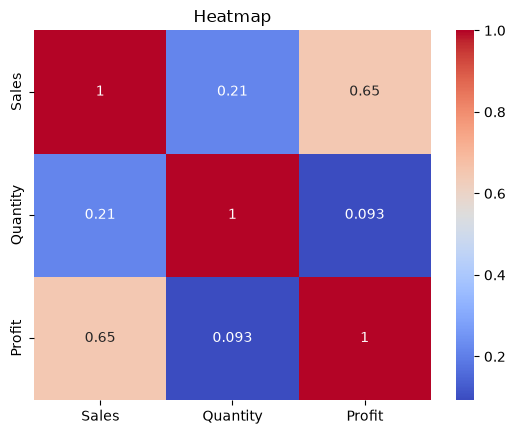

In [9]:
corr = df_copy[["Sales", "Quantity", "Profit"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Heatmap")
plt.show()

# Cleaning Data

## Missing Value

In [10]:
'''
Kode isnull() digunakan untuk mencari missing value disetiap kolom
'''
# Jumlah missing value
Missing = df_copy.isnull().sum()
print(f"Missing Value:")
print(Missing)

Missing Value:
Order ID        0
Order Date      0
Ship Date       0
EmailID         0
Geography       0
Category        0
Product Name    0
Sales           0
Quantity        0
Profit          0
Order_Year      0
Ship_Year       0
dtype: int64


------------------------
Pada analisis di data Amazon ini bisa dilihat bahwa tidak ditemukannya data yang missing value disetiap kolom data tersebut.

## Outlier

## Encoder

In [11]:
le = LabelEncoder()

In [12]:
'''
Kode le.fit_transform() digunakan untuk mengubah data string menjadi data integer.
'''
df_copy["OrderID_Coder"] = le.fit_transform(df["Order ID"])
df_copy["OrderDate_Coder"] = le.fit_transform(df["Order Date"])
df_copy["ShipDate_Coder"] = le.fit_transform(df["Ship Date"])
df_copy["EmailID_Coder"] = le.fit_transform(df["EmailID"])
df_copy["Geography_Coder"] = le.fit_transform(df["Geography"])
df_copy["Category_Coder"] = le.fit_transform(df["Category"])
df_copy["ProductName_Coder"] = le.fit_transform(df["Product Name"])
df_copy

,Order ID,Order Date,Ship Date,EmailID,Geography,Category,Product Name,Sales,Quantity,Profit,Order_Year,Ship_Year,OrderID_Coder,OrderDate_Coder,ShipDate_Coder,EmailID_Coder,Geography_Coder,Category_Coder,ProductName_Coder
0,CA-2013-138688,2013-06-13,2013-06-17,DarrinVanHuff@gmail.com,"United States,Los Angeles,California",Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,2,6.8714,2013,2013,755,467,495,173,80,10,1164
1,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.860,7,14.1694,2011,2011,68,63,64,96,80,9,464
2,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Art,Newell 322,7.280,4,1.9656,2011,2011,68,63,64,96,80,2,915
3,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Phones,Mitel 5320 IP Phone VoIP phone,907.152,4,90.7152,2011,2011,68,63,64,96,80,13,884
4,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Binders,DXL Angle-View Binders with Locking Rings by S...,18.504,3,5.7825,2011,2011,68,63,64,96,80,3,404
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3198,CA-2013-125794,2013-09-30,2013-10-04,MarisLaWare@gmail.com,"United States,Los Angeles,California",Accessories,Memorex Mini Travel Drive 64 GB USB 2.0 Flash ...,36.240,1,15.2208,2013,2013,692,535,576,433,80,0,870
3199,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2,15.6332,2014,2014,1062,637,683,174,31,9,1237
3200,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Phones,Aastra 57i VoIP phone,258.576,2,19.3932,2014,2014,1062,637,683,174,31,13,36
3201,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4,13.3200,2014,2014,1062,637,683,174,31,12,754


### Boxplot

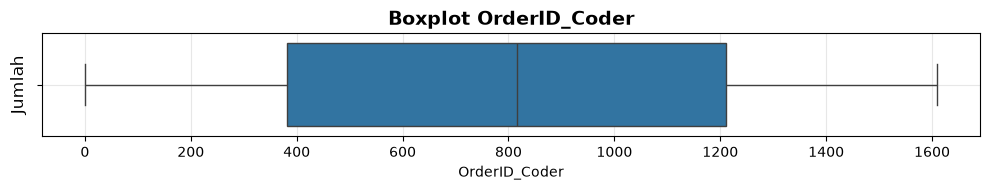

In [13]:
'''
Kode boxplot() digunakan untuk mencari outlier
'''
# Buat copy data lagi
df_box = df_copy.copy()

# Buat boxplot OrderID_Coder
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["OrderID_Coder"])
plt.title("Boxplot OrderID_Coder", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

Pada analisisa data diatas tidak terdapat outlier pada data OrderID_Coder.

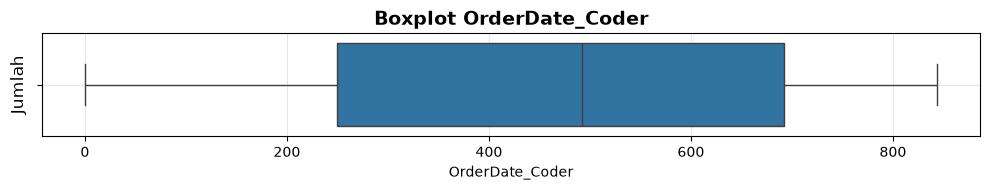

In [14]:
'''
Kode boxplot() digunakan untuk mencari outlier
'''
# Buat boxplot OrderID_Coder
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["OrderDate_Coder"])
plt.title("Boxplot OrderDate_Coder", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

Pada analisisa data diatas tidak terdapat outlier pada data OrderDate_Coder.

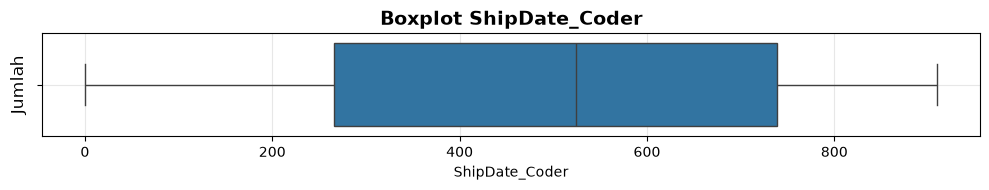

In [15]:
'''
Kode boxplot() digunakan untuk mencari outlier
'''
# Buat boxplot OrderID_Coder
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["ShipDate_Coder"])
plt.title("Boxplot ShipDate_Coder", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=" * 100)

Pada analisisa data diatas tidak terdapat outlier pada data ShipDate_Coder.

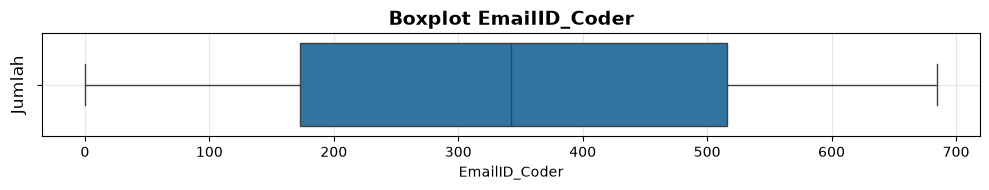

In [16]:
'''
Kode boxplot() digunakan untuk mencari outlier
'''
# Buat boxplot OrderID_Coder
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["EmailID_Coder"])
plt.title("Boxplot EmailID_Coder", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Pada analisisa data diatas tidak terdapat outlier pada data EmailID_Coder.

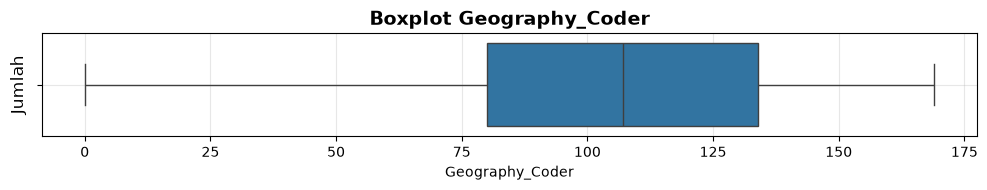

In [17]:
'''
Kode boxplot() digunakan untuk mencari outlier
'''
# Buat boxplot OrderID_Coder
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["Geography_Coder"])
plt.title("Boxplot Geography_Coder", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Pada analisisa data diatas tidak terdapat outlier pada data Geography_Coder.

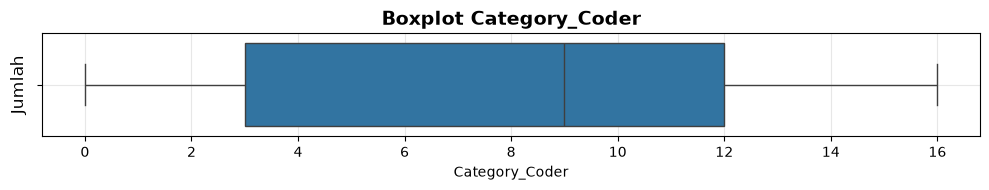

In [18]:
'''
Kode boxplot() digunakan untuk mencari outlier
'''
# Buat boxplot OrderID_Coder
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["Category_Coder"])
plt.title("Boxplot Category_Coder", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Pada analisisa data diatas tidak terdapat outlier pada data Category_Coder.

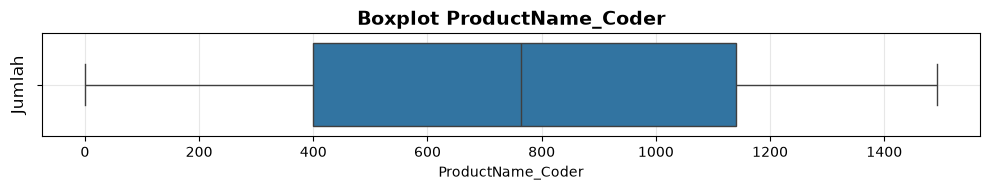

In [19]:
'''
Kode boxplot() digunakan untuk mencari outlier
'''
# Buat boxplot OrderID_Coder
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["ProductName_Coder"])
plt.title("Boxplot ProductName_Coder", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Pada analisisa data diatas tidak terdapat outlier pada data ProductName_Coder.

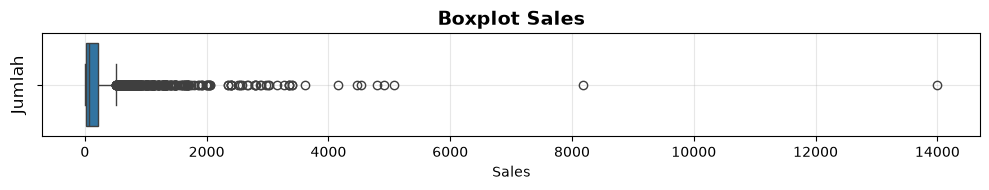

In [20]:
'''
Kode boxplot() digunakan untuk mencari outlier
'''
# Buat boxplot OrderID_Coder
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["Sales"])
plt.title("Boxplot Sales", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Pada analisisa data diatas terdapat outlier pada data Sales.

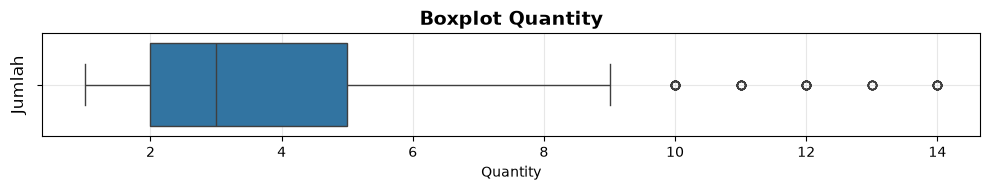

In [21]:
'''
Kode boxplot() digunakan untuk mencari outlier
'''
# Buat boxplot OrderID_Coder
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["Quantity"])
plt.title("Boxplot Quantity", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Pada analisisa data diatas terdapat outlier pada data Quantity.

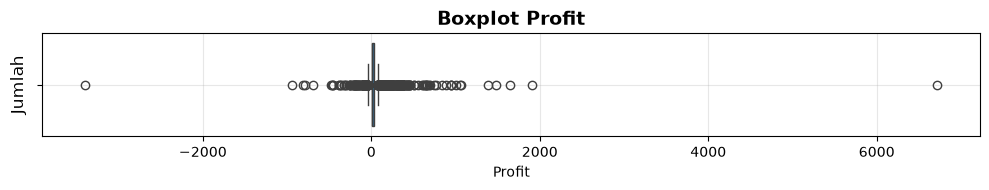

In [22]:
'''
Kode boxplot() digunakan untuk mencari outlier
'''
# Buat boxplot OrderID_Coder
plt.figure(figsize=(10, 2)) 
sns.boxplot(x=df_box["Profit"])
plt.title("Boxplot Profit", fontsize=14, fontweight="bold")
plt.ylabel("Jumlah", fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Pada analisisa data diatas terdapat outlier pada data Profit.

### Sales

In [23]:
'''
Saya menggunakan zscore pada Kolom Sales untuk mencari Outlier dengan mencari dengan membuat kolom baru dan mencari 
nilai yang lebih atau kurang dari 2
'''
dfZSales = df_copy
dfZSales["z_Score_Sales"] = zscore(dfZSales["Sales"])
#Mencari Outlier dengan menghitung nilai absolut yang lebih besar dari 2
Outlier_Sales = dfZSales[dfZSales["z_Score_Sales"].abs()>2]
Outlier_Sales

,Order ID,Order Date,Ship Date,EmailID,Geography,Category,Product Name,Sales,Quantity,Profit,Order_Year,Ship_Year,OrderID_Coder,OrderDate_Coder,ShipDate_Coder,EmailID_Coder,Geography_Coder,Category_Coder,ProductName_Coder,z_Score_Sales
6,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Tables,Chromcraft Rectangular Conference Tables,1706.184,9,85.3092,2011,2011,68,63,64,96,80,16,349,2.819560
72,CA-2013-145625,2013-09-12,2013-09-18,KellyCollister@gmail.com,"United States,San Diego,California",Accessories,LogitechÂ P710e Mobile Speakerphone,3347.370,13,636.0003,2013,2013,791,521,563,377,133,0,829,5.946850
111,US-2011-135972,2011-09-21,2011-09-23,JackGarza@gmail.com,"United States,Des Moines,Washington",Copiers,Canon PC1080F Personal Copier,1799.970,3,701.9883,2011,2011,1398,118,119,288,36,6,326,2.998270
120,CA-2014-117457,2014-12-09,2014-12-13,KeithHerrera@gmail.com,"United States,San Francisco,California",Bookcases,O'Sullivan 4-Shelf Bookcase in Odessa Pine,1336.829,13,31.4548,2014,2014,1032,827,891,375,134,4,960,2.115752
161,CA-2014-127432,2014-01-23,2014-01-28,AlanDominguez@gmail.com,"United States,Great Falls,Montana",Copiers,Canon Image Class D660 Copier,2999.950,5,1379.9770,2014,2014,1107,619,663,10,52,6,322,5.284839
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3084,CA-2013-107104,2013-11-27,2013-12-01,MaribethSchnelling@gmail.com,"United States,Los Angeles,California",Bookcases,DMI Eclipse Executive Suite Bookcases,3406.664,8,160.3136,2013,2013,604,579,623,430,80,4,403,6.059835
3091,CA-2013-160717,2013-06-07,2013-06-12,MariaEtezadi@gmail.com,"United States,Santa Barbara,California",Phones,Samsung Galaxy Mega 6.3,3023.928,9,226.7946,2013,2013,873,462,491,427,140,13,1131,5.330529
3134,CA-2013-146913,2013-11-01,2013-11-06,SylviaFoulston@gmail.com,"United States,San Francisco,California",Chairs,Office Star - Professional Matrix Back Chair w...,1403.920,5,70.1960,2013,2013,800,558,600,632,134,5,982,2.243594
3161,CA-2012-164301,2012-03-26,2012-03-30,EllisBallard@gmail.com,"United States,Seattle,Washington",Tables,Bush Advantage Collection Racetrack Conference...,3393.680,8,610.8624,2012,2012,544,222,235,218,145,16,305,6.035094


#### Jumlah Outlier Sales

In [24]:
'''
Setelah mencari Outleir, saya menghitung Total Outleir yang ditemukan dan menghitung Outleir sales per Category
'''
ZSales = (dfZSales["z_Score_Sales"].abs()>2).sum()
#Buat jadi %
a = ZSales / len(df_copy) * 100

print("=" * 50)
print("Jumlah Outlier Sales")
print(f"Outlier Profit: {ZSales}")
print(f"Outlier Profit persen: {a:.2f}%")
#Menghitung Outlier per Category
print("=" * 50)
outlier_per_category = dfZSales[dfZSales["z_Score_Sales"].abs() > 2].groupby("Category")["z_Score_Sales"].count()
print("Jumlah Outlier Sales per Category:")
print(outlier_per_category)
print("=" * 50)

Jumlah Outlier Sales
Outlier Profit: 106
Outlier Profit persen: 3.31%
Jumlah Outlier Sales per Category:
Category
Accessories     8
Appliances      6
Binders         9
Bookcases       8
Chairs         16
Copiers        10
Machines       11
Phones         10
Storage         5
Supplies        3
Tables         20
Name: z_Score_Sales, dtype: int64


Pada data Amazon terdapat 145 Outlier di bagian Quantity dengan category Tables yang paling banyak muncul Outliernya 
sebanyak 20, dan category Supplies yang paling sedikit muncul Outlier sebanyak 3

### Quantity

In [25]:
'''
Saya menggunakan zscore pada Kolom Quantity untuk mencari Outlier dengan mencari dengan membuat kolom baru dan mencari 
nilai yang lebih atau kurang dari 2
'''

dfZQuantity = df_copy
dfZQuantity["z_Score_Quantity"] = zscore(dfZQuantity["Quantity"])
Outlier_Quantity = dfZQuantity[dfZQuantity["z_Score_Quantity"].abs()>2]
Outlier_Quantity

,Order ID,Order Date,Ship Date,EmailID,Geography,Category,Product Name,Sales,Quantity,Profit,...,Ship_Year,OrderID_Coder,OrderDate_Coder,ShipDate_Coder,EmailID_Coder,Geography_Coder,Category_Coder,ProductName_Coder,z_Score_Sales,z_Score_Quantity
6,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Tables,Chromcraft Rectangular Conference Tables,1706.184,9,85.3092,...,2011,68,63,64,96,80,16,349,2.819560,2.287492
44,CA-2013-145583,2013-10-14,2013-10-20,LenaCreighton@gmail.com,"United States,Roseville,California",Furnishings,Longer-Life Soft White Bulbs,43.120,14,20.6976,...,2013,790,544,586,399,126,9,832,-0.349419,4.499300
72,CA-2013-145625,2013-09-12,2013-09-18,KellyCollister@gmail.com,"United States,San Diego,California",Accessories,LogitechÂ P710e Mobile Speakerphone,3347.370,13,636.0003,...,2013,791,521,563,377,133,0,829,5.946850,4.056938
107,US-2011-119137,2011-07-23,2011-07-27,ArthurGainer@gmail.com,"United States,Tucson,Arizona",Accessories,Microsoft Natural Keyboard Elite,479.040,10,-29.9400,...,2011,1384,86,88,50,158,0,880,0.481229,2.729853
118,CA-2014-117457,2014-12-09,2014-12-13,KeithHerrera@gmail.com,"United States,San Francisco,California",Labels,Self-Adhesive Removable Labels,28.350,9,13.6080,...,2014,1032,827,891,375,134,10,1165,-0.377563,2.287492
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3091,CA-2013-160717,2013-06-07,2013-06-12,MariaEtezadi@gmail.com,"United States,Santa Barbara,California",Phones,Samsung Galaxy Mega 6.3,3023.928,9,226.7946,...,2013,873,462,491,427,140,13,1131,5.330529,2.287492
3103,CA-2012-130113,2012-12-27,2012-12-31,AaronHawkins@gmail.com,"United States,San Francisco,California",Phones,Geemarc AmpliPOWER60,668.160,9,75.1680,...,2012,382,383,407,1,134,13,593,0.841599,2.287492
3182,CA-2014-164028,2014-11-25,2014-12-01,JohnLee@gmail.com,"United States,San Francisco,California",Accessories,Memorex Mini Travel Drive 16 GB USB 2.0 Flash ...,223.580,14,87.1962,...,2014,1334,815,880,333,134,0,868,-0.005551,4.499300
3183,CA-2011-143371,2011-12-28,2012-01-03,MaribethDona@gmail.com,"United States,Anaheim,California",Storage,"Carina Mini System Audio Rack, Model AR050B",998.820,9,29.9646,...,2012,177,190,201,429,1,14,341,1.471673,2.287492


#### Jumlah Outlier Quantity

In [26]:
'''
Setelah mencari Outleir, saya menghitung Total Outleir yang ditemukan dan menghitung Outleir Quantity per Category
'''
ZQuantity = (dfZQuantity["z_Score_Quantity"].abs()>2).sum()
#Buat jadi %
a = ZQuantity / len(df_copy) * 100
print(f"Outlier Quantity: {ZQuantity}")
print(f"Outlier Quantity persen: {a:.2f}%")
#Menghitung Outlier per Category
print("=" * 50)
Outlier_Quantity_per_Category = dfZQuantity[dfZQuantity["z_Score_Quantity"].abs() > 2].groupby("Category")["z_Score_Quantity"].count()
print("Jumlah Outlier Quantity per Category:")
print(Outlier_Quantity_per_Category)
print("=" * 50)

Outlier Quantity: 145
Outlier Quantity persen: 4.53%
Jumlah Outlier Quantity per Category:
Category
Accessories    18
Appliances      4
Art             9
Binders        23
Bookcases       3
Chairs          4
Envelopes       1
Fasteners       1
Furnishings    13
Labels          7
Machines        2
Paper          20
Phones         12
Storage        17
Tables         11
Name: z_Score_Quantity, dtype: int64


Pada data Amazon terdapat 145 Outlier di bagian Quantity dengan category Binders yang paing banyak muncul Outliernya sebesar 23,
dan category Machines yang paling sedikit muncul Outlier sebesar 2

### Profit

In [27]:
'''
Saya menggunakan zscore pada Kolom Profit untuk mencari Outlier dengan mencari dengan membuat kolom baru dan mencari 
nilai yang lebih atau kurang dari 2
'''
dfZProfit = df_copy
dfZProfit["z_Score_Profit"] = zscore(dfZProfit["Profit"])
Outlier_Profit = dfZProfit[dfZProfit["z_Score_Profit"].abs()>2]
Outlier_Profit

,Order ID,Order Date,Ship Date,EmailID,Geography,Category,Product Name,Sales,Quantity,Profit,...,OrderID_Coder,OrderDate_Coder,ShipDate_Coder,EmailID_Coder,Geography_Coder,Category_Coder,ProductName_Coder,z_Score_Sales,z_Score_Quantity,z_Score_Profit
72,CA-2013-145625,2013-09-12,2013-09-18,KellyCollister@gmail.com,"United States,San Diego,California",Accessories,LogitechÂ P710e Mobile Speakerphone,3347.370,13,636.0003,...,791,521,563,377,133,0,829,5.946850,4.056938,3.459011
111,US-2011-135972,2011-09-21,2011-09-23,JackGarza@gmail.com,"United States,Des Moines,Washington",Copiers,Canon PC1080F Personal Copier,1799.970,3,701.9883,...,1398,118,119,288,36,6,326,2.998270,-0.366678,3.838074
114,CA-2014-117457,2014-12-09,2014-12-13,KeithHerrera@gmail.com,"United States,San Francisco,California",Copiers,Sharp AL-1530CS Digital Copier,1199.976,3,434.9913,...,1032,827,891,375,134,6,1175,1.854977,-0.366678,2.304331
134,CA-2013-109869,2013-04-23,2013-04-30,TanjaNorvell@gmail.com,"United States,Phoenix,Arizona",Tables,Bush Advantage Collection Racetrack Conference...,1272.630,6,-814.4832,...,620,435,463,637,107,16,305,1.993420,0.960407,-4.873179
161,CA-2014-127432,2014-01-23,2014-01-28,AlanDominguez@gmail.com,"United States,Great Falls,Montana",Copiers,Canon Image Class D660 Copier,2999.950,5,1379.9770,...,1107,619,663,10,52,6,322,5.284839,0.518045,7.732728
200,CA-2011-131450,2011-08-08,2011-08-15,LenaRadford@gmail.com,"United States,San Diego,California",Copiers,Sharp AL-1530CS Digital Copier,1199.976,3,434.9913,...,126,95,100,401,133,6,1175,1.854977,-0.366678,2.304331
259,CA-2014-143686,2014-05-15,2014-05-15,PaulineJohnson@gmail.com,"United States,Santa Ana,California",Accessories,Razer Tiamat Over Ear 7.1 Surround Sound PC Ga...,1399.930,7,601.9699,...,1225,687,731,523,139,0,1085,2.235991,1.402768,3.263526
413,US-2012-103471,2012-12-24,2012-12-28,JimRadford@gmail.com,"United States,Colorado Springs,Colorado",Bookcases,"Atlantic Metals Mobile 4-Shelf Bookcases, Cust...",590.058,7,-786.7440,...,1421,381,404,325,28,4,139,0.692775,1.402768,-4.713833
503,CA-2014-108560,2014-07-09,2014-07-16,JennaCaffey@gmail.com,"United States,Kent,Washington",Labels,"Dot Matrix Printer Tape Reel Labels, White, 50...",786.480,8,385.3752,...,994,720,771,306,61,10,433,1.067058,1.845130,2.019315
507,CA-2012-157084,2012-12-19,2012-12-24,JamesGalang@gmail.com,"United States,Los Angeles,California",Accessories,Plantronics Savi W720 Multi-Device Wireless He...,1265.850,3,556.9740,...,522,378,402,291,80,0,1041,1.980501,-0.366678,3.005051


#### Jumlah Outlier Profit

In [28]:
'''
Setelah mencari Outleir, saya menghitung Total Outleir yang ditemukan dan menghitung Outleir Profit per Category
'''
ZProfit = (dfZProfit["z_Score_Profit"].abs()>2).sum()
#Buat jadi %
a = ZProfit / len(df_copy) * 100
print("=" * 50)
print(f"Outlier Profit: {ZProfit}")
print(f"Outlier Profit persen: {a:.2f}%")
#Menghitung Outlier per Category
print("=" * 50)
Outlier_Profit_per_Category = dfZProfit[dfZProfit["z_Score_Profit"].abs() > 2].groupby("Category")["z_Score_Profit"].count()
print("Jumlah Outlier Profit per Category:")
print(Outlier_Profit_per_Category)
print("=" * 50)

Outlier Profit: 59
Outlier Profit persen: 1.84%
Jumlah Outlier Profit per Category:
Category
Accessories     8
Appliances      7
Binders        11
Bookcases       5
Copiers        13
Labels          1
Machines        6
Tables          8
Name: z_Score_Profit, dtype: int64


## Konsistensi

#### Order ID

In [29]:
'''
Untuk mencari data yang typo, saya menggunakan kode unique() yang digunakan untuk Mmengambil semua nilai unik (tidak berulang)
dari kolom tersebut
'''
TypoOrderID = df_copy["Order ID"].unique()
print(f"Typo Order ID: {TypoOrderID}")
print("=" * 50)

Typo Order ID: <ArrowStringArray>
['CA-2013-138688', 'CA-2011-115812', 'CA-2013-161389', 'CA-2011-167164',
 'CA-2011-143336', 'CA-2012-106320', 'CA-2013-121755', 'CA-2013-101343',
 'CA-2012-135545', 'CA-2011-106376',
 ...
 'CA-2013-164889', 'CA-2014-164028', 'CA-2011-143371', 'CA-2012-145415',
 'CA-2012-141593', 'CA-2014-137421', 'US-2013-103674', 'CA-2013-125794',
 'CA-2014-121258', 'CA-2014-119914']
Length: 1611, dtype: str


Pada bagian Order ID, tidak terdapat data yang typo ataupun error

#### Order Date

In [30]:
'''
Untuk mencari data yang typo, saya menggunakan kode unique() yang digunakan untuk Mmengambil semua nilai unik (tidak berulang)
dari kolom tersebut
'''
TypoOrderDate = df_copy["Order Date"].unique()
print(f"Typo Order Date: {TypoOrderDate}")
print("=" * 50)

Typo Order Date: <DatetimeArray>
['2013-06-13 00:00:00', '2011-06-09 00:00:00', '2013-12-06 00:00:00',
 '2011-05-13 00:00:00', '2011-08-27 00:00:00', '2012-09-25 00:00:00',
 '2013-01-16 00:00:00', '2013-07-18 00:00:00', '2012-11-24 00:00:00',
 '2011-12-05 00:00:00',
 ...
 '2011-06-18 00:00:00', '2011-08-15 00:00:00', '2014-06-20 00:00:00',
 '2012-03-26 00:00:00', '2011-04-03 00:00:00', '2012-09-13 00:00:00',
 '2013-09-05 00:00:00', '2013-06-04 00:00:00', '2011-12-28 00:00:00',
 '2012-04-12 00:00:00']
Length: 845, dtype: datetime64[us]


Pada bagian Order Date, tidak terdapat data yang typo ataupun error

#### Ship Date

In [31]:
'''
Untuk mencari data yang typo, saya menggunakan kode unique() yang digunakan untuk Mmengambil semua nilai unik (tidak berulang)
dari kolom tersebut
'''
TypoShipDate = df_copy["Ship Date"].unique()
print(f"Typo Ship Date: {TypoShipDate}")
print("=" * 50)

Typo Ship Date: <DatetimeArray>
['2013-06-17 00:00:00', '2011-06-14 00:00:00', '2013-12-11 00:00:00',
 '2011-05-15 00:00:00', '2011-09-01 00:00:00', '2012-09-30 00:00:00',
 '2013-01-20 00:00:00', '2013-07-23 00:00:00', '2012-11-30 00:00:00',
 '2011-12-10 00:00:00',
 ...
 '2013-05-20 00:00:00', '2011-03-12 00:00:00', '2014-01-05 00:00:00',
 '2014-10-24 00:00:00', '2013-07-03 00:00:00', '2011-06-23 00:00:00',
 '2011-08-19 00:00:00', '2011-04-08 00:00:00', '2014-12-01 00:00:00',
 '2014-03-04 00:00:00']
Length: 911, dtype: datetime64[us]


Pada bagian Ship Date, tidak terdapat data yang typo ataupun error

#### EmailID

In [32]:
'''
Untuk mencari data yang typo, saya menggunakan kode unique() yang digunakan untuk Mmengambil semua nilai unik (tidak berulang)
dari kolom tersebut
'''
TypoEmailID = df_copy["EmailID"].unique()
print(f"Typo Email ID: {TypoEmailID}")
print("=" * 50)

Typo Email ID: <ArrowStringArray>
[    'DarrinVanHuff@gmail.com',    'BrosinaHoffman@gmail.com',
       'IreneMaddox@gmail.com',    'AlejandroGrove@gmail.com',
 'ZuschussDonatelli@gmail.com',        'EmilyBurns@gmail.com',
      'EricHoffmann@gmail.com',       'RubenAusman@gmail.com',
       'KunstMiller@gmail.com',      'BrendanSweed@gmail.com',
 ...
   'TheonePippenger@gmail.com',     'CraigMolinari@gmail.com',
     'FredWasserman@gmail.com',          'JoySmith@gmail.com',
      'EvanBailliet@gmail.com',     'TroyBlackwell@gmail.com',
         'DanLawera@gmail.com',         'SungChung@gmail.com',
      'MaribethDona@gmail.com',         'AnnePryor@gmail.com']
Length: 686, dtype: str


Pada bagian EmailID, tidak terdapat data yang typo ataupun error

#### Geography

In [33]:
'''
Untuk mencari data yang typo, saya menggunakan kode unique() yang digunakan untuk Mmengambil semua nilai unik (tidak berulang)
dari kolom tersebut
'''
TypoGeography = df_copy["Geography"].unique()
print(f"Typo Geography: {TypoGeography}")
print("=" * 50)

Typo Geography: <ArrowStringArray>
[    'United States,Los Angeles,California',
         'United States,Seattle,Washington',
           'United States,West Jordan,Utah',
   'United States,San Francisco,California',
                  'United States,Orem,Utah',
            'United States,Gilbert,Arizona',
            'United States,Portland,Oregon',
            'United States,Aurora,Colorado',
            'United States,Phoenix,Arizona',
       'United States,Roseville,California',
 ...
         'United States,Modesto,California',
          'United States,Longmont,Colorado',
           'United States,Davis,California',
     'United States,Morgan Hill,California',
           'United States,Greeley,Colorado',
           'United States,Twin Falls,Idaho',
    'United States,San Clemente,California',
          'United States,Dublin,California',
 'United States,San Luis Obispo,California',
            'United States,Lodi,California']
Length: 170, dtype: str


Pada bagian Geography, tidak terdapat data yang typo ataupun error

#### Category

In [34]:
'''
Untuk mencari data yang typo, saya menggunakan kode unique() yang digunakan untuk Mmengambil semua nilai unik (tidak berulang)
dari kolom tersebut
'''
TypoCategory = df_copy["Category"].unique()
print(f"Typo Category: {TypoCategory}")
print("=" * 50)

Typo Category: <ArrowStringArray>
[     'Labels', 'Furnishings',         'Art',      'Phones',     'Binders',
  'Appliances',      'Tables',     'Storage', 'Accessories',       'Paper',
      'Chairs',   'Fasteners',    'Supplies',   'Envelopes',     'Copiers',
   'Bookcases',    'Machines']
Length: 17, dtype: str


Pada bagian Category, tidak terdapat data yang typo ataupun error

#### Product Name

In [35]:
'''
untuk mencari data yang typo, saya menggunakan kode unique() yang digunakan untuk Mmengambil semua nilai unik (tidak berulang)
dari kolom tersebut
'''
TypoProductName = df_copy["Product Name"].unique()
print(f"Typo Produk Name: {TypoProductName}")
print("=" * 50)

Typo Produk Name: <ArrowStringArray>
[                        'Self-Adhesive Address Labels for Typewriters by Universal',
                  'Eldon Expressions Wood and Plastic Desk Accessories, Cherry Wood',
                                                                        'Newell 322',
                                                    'Mitel 5320 IP Phone VoIP phone',
                              'DXL Angle-View Binders with Locking Rings by Samsill',
                                                  'Belkin F5C206VTEL 6 Outlet Surge',
                                          'Chromcraft Rectangular Conference Tables',
                                   'Konftel 250 ConferenceÂ phoneÂ - Charcoal black',
                                       'Fellowes PB200 Plastic Comb Binding Machine',
                                                        'Fellowes Super Stor/Drawer',
 ...
 'Acme Hot Forged Carbon Steel Scissors with Nickel-Plated Handles, 3 7/8" Cut, 8"L',
            

Pada bagian Product Name, tidak terdapat data yang typo ataupun error

## Duplicated

In [36]:
'''
Saya menggunakan kode duplicated untuk mencari data yang terdapat duplikate (data yang sama), setelah meancari saya mengubah jumlah
data menjadi persen.
'''
## Duplicated 
SemuaData = df_copy.duplicated().sum()

#Buat jadi %
a = SemuaData / len(df_copy) * 100
print("=" * 50)
print(f"Duplikat: {SemuaData}")
print(f"Duplikat persen: {a:.2f}%")
print("=" * 50)

Duplikat: 0
Duplikat persen: 0.00%


Setelah menggunakan kode duplicated untuk mencari duplikat, tidak terdapat data yang duplikat di semua data.

# Data Cleaning + Data Manipulation

# EDA Setelah cleaning

## Unvariate

<Figure size 1200x800 with 0 Axes>

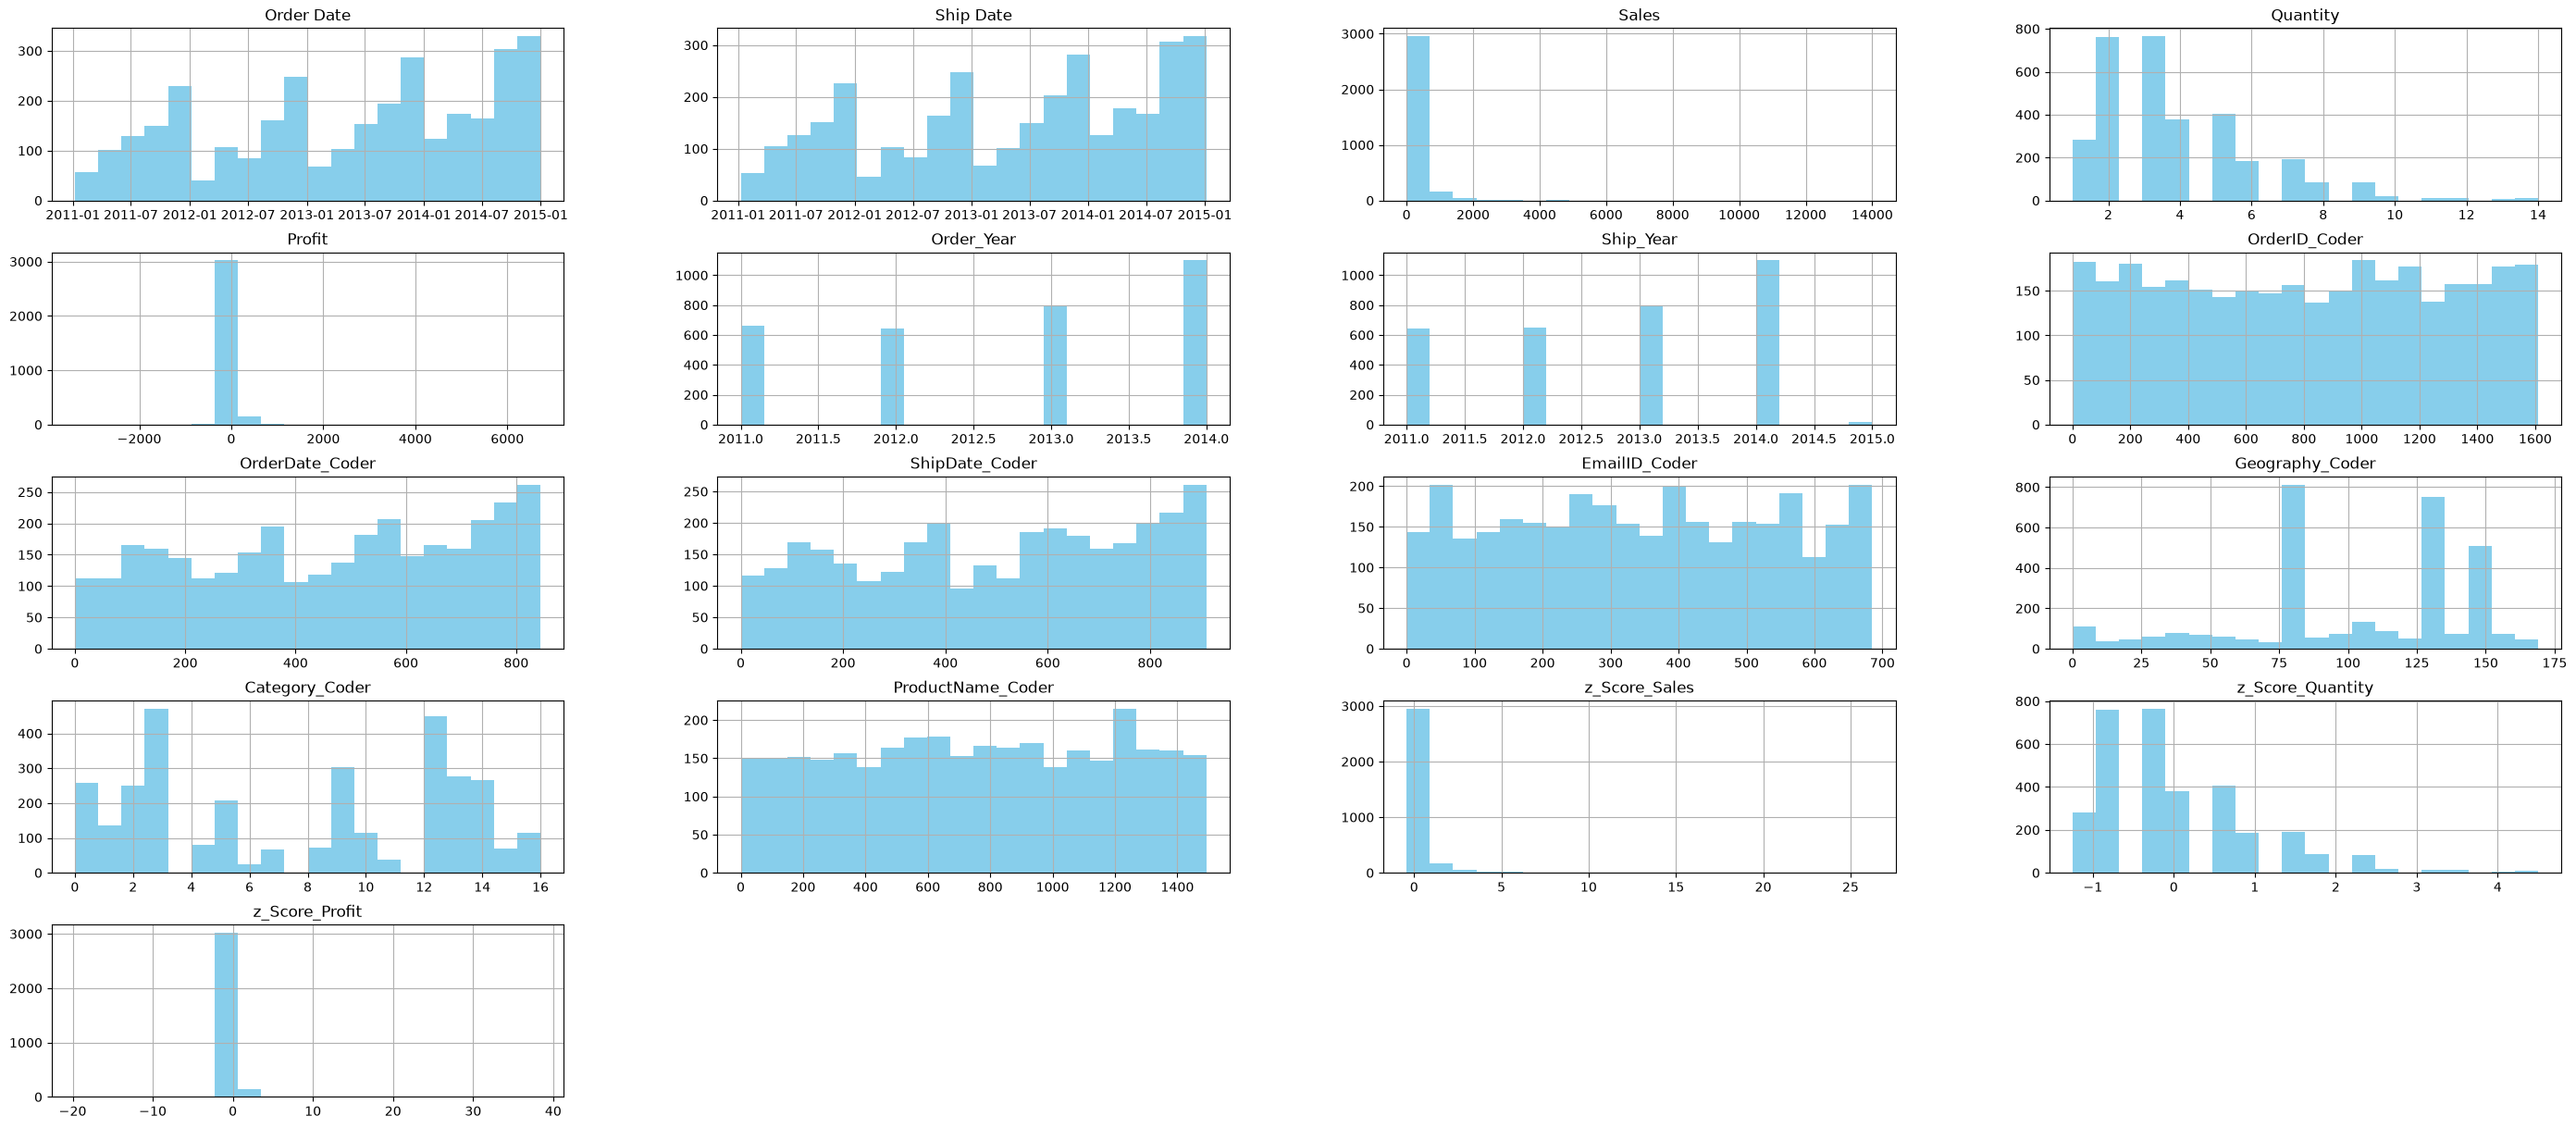

In [54]:
'''
Untuk pembuatan Unvariate itu menggunakan kode df_copy.hist, dengan bertujuan untuk membuat barplot dengan terpisah
'''

plt.figure(figsize=(12,8))
df_copy.hist(bins = 20, figsize = (35,15), color = "skyblue")
plt.title("Distribusi Variable Numerik")
plt.show()

## Heatmap sesudah cleaning

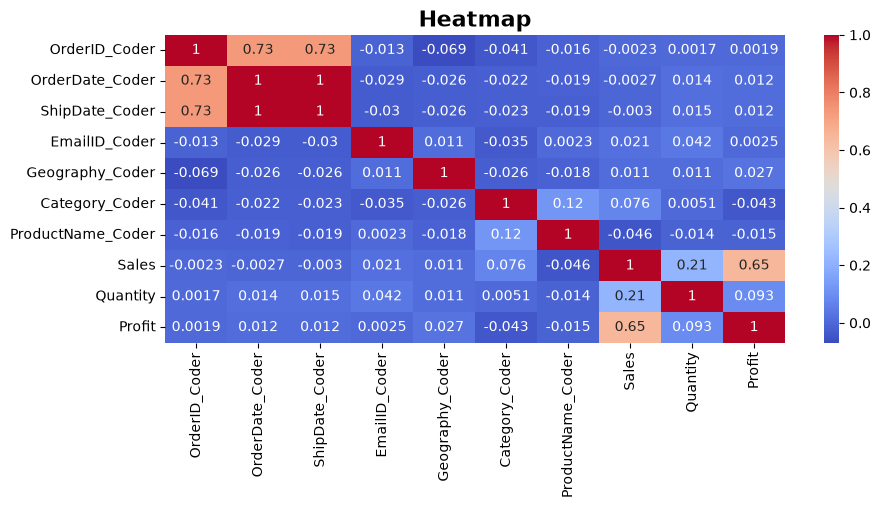

In [55]:
'''
Untuk pembuatan Heatmap itu menggunakan kode sns.heatmap.
'''

corr = df_copy[["OrderID_Coder", "OrderDate_Coder", "ShipDate_Coder","EmailID_Coder","Geography_Coder","Category_Coder","ProductName_Coder","Sales", "Quantity", "Profit"]].corr()
plt.figure(figsize=(10, 4)) 
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Heatmap",fontsize=16, fontweight="bold")
plt.show()

OrderDate vs ShipDate (1.00): Ini adalah korelasi tertinggi, Ini  karena tanggal pengiriman biasanya sangat ditentukan oleh tanggal pemesanan. 

Sales vs Quantity (0.21): Korelasi positif lemah, Menunjukkan bahwa jumlah barang yang dibeli (Quantity) sedikit mempengaruhi total penjualan.

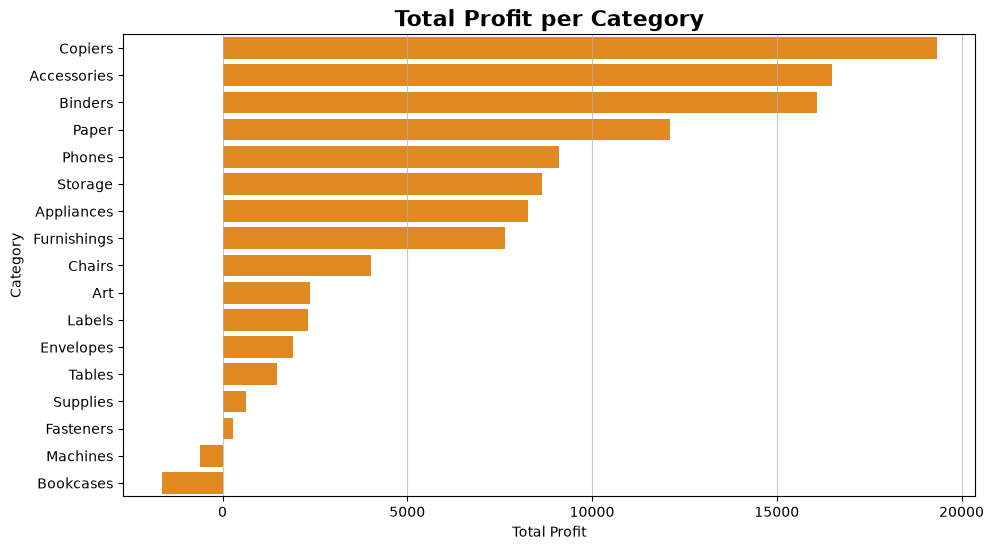

,Category,Profit
0,Copiers,19327.24
1,Accessories,16484.60
2,Binders,16096.80
3,Paper,12119.24
4,Phones,9110.74
5,Storage,8645.32
6,Appliances,8261.27
7,Furnishings,7641.27
8,Chairs,4027.58
9,Art,2374.10


In [59]:
'''
Untuk pembuatan Barplot itu menggunakan kode sns.barplot, dengan warna orange gelap dan grip sebagai garis penanda.
'''

# Menghitung total profit per kategori dan mengurutkannya dengan menggunakan groupby
profit_per_category = df_copy.groupby("Category")["Profit"].sum().sort_values(ascending=False).reset_index().round(2)

# Barchart
plt.figure(figsize=(11, 6))
sns.barplot(x="Profit", y="Category", data=profit_per_category, color="darkorange")
plt.title("Total Profit per Category", fontsize=16, fontweight="bold")
plt.xlabel("Total Profit")
plt.ylabel("Category")
plt.grid(axis="x", alpha=0.7)
plt.show()
print("="*25)
profit_per_category

Pada barplot disamping bisa disimpulkan bahwa **Copiers memiliki Jumlah total Profit sebesar 19327.24.** Setelah itu pada bagain **Bookcases Ini adalah "lubang" terbesar dalam laporan laba rugi kategori Kerugian di sini cukup signifikan sebesar -1.646,51.**

## Scatter Plot

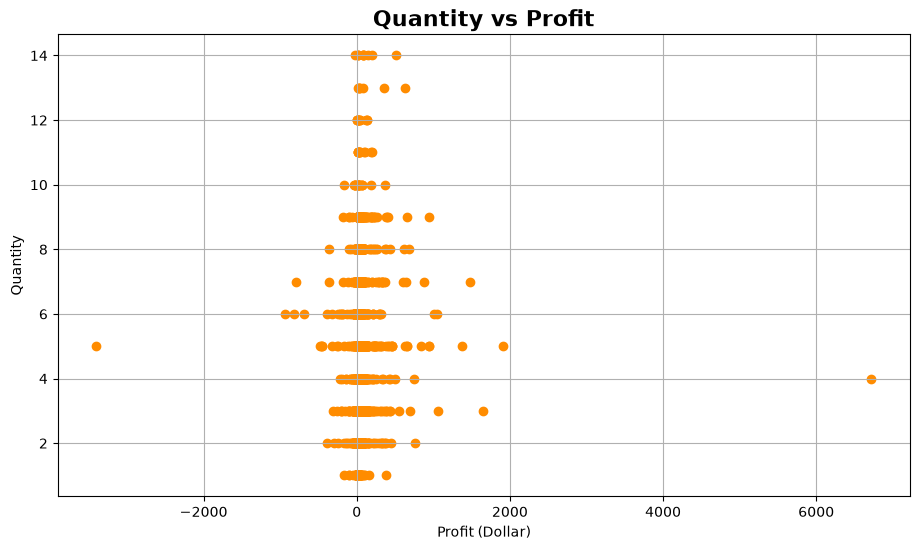

Quantity,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Profit,,,,,,,,,,,,,,
-3399.9800,NaN,NaN,NaN,NaN,-3399.980,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
-938.2800,NaN,NaN,NaN,NaN,NaN,-938.2800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
-814.4832,NaN,NaN,NaN,NaN,NaN,-814.4832,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
-786.7440,NaN,NaN,NaN,NaN,NaN,NaN,-786.7440,NaN,NaN,NaN,NaN,NaN,NaN,NaN
-694.2936,NaN,NaN,NaN,NaN,NaN,-694.2936,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1379.9770,NaN,NaN,NaN,NaN,1379.977,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1480.4671,NaN,NaN,NaN,NaN,NaN,NaN,1480.4671,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1644.2913,NaN,NaN,1644.2913,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [58]:
'''
Untuk pembuatan scatterplot itu menggunakan kode plt.scatter, dengan warna orange gelap dan grip sebagai garis penanda.
'''

# Membuat count plot
plt.figure(figsize=(11, 6))
plt.scatter(df_copy["Profit"], df_copy["Quantity"], color="darkorange")
plt.title("Quantity vs Profit", fontsize=16, fontweight="bold")
plt.xlabel("Profit (Dollar)")
plt.ylabel("Quantity")
plt.grid(True)
plt.show()

# Membuat cross tabulation
cross_profit = pd.crosstab(
    df["Profit"],
    df["Quantity"],
    values=df["Profit"],
    aggfunc="sum"
)
cross_profit

Pada Scatter Plot bisa disimpukan bahwa **Quantity (5) memiliki profit sekitar -3000 lebih,** ini adalah anomali karena barang tiba-tiba menyebabkan kerugian yang sangat besar. Setelah itu pada bagain **Quantity (4) memiliki profit sangat tinggi, mencapai sekitar +6500 lebih.** Ini juga anomali karena menghasilkan keuntungan yang jauh lebih besar

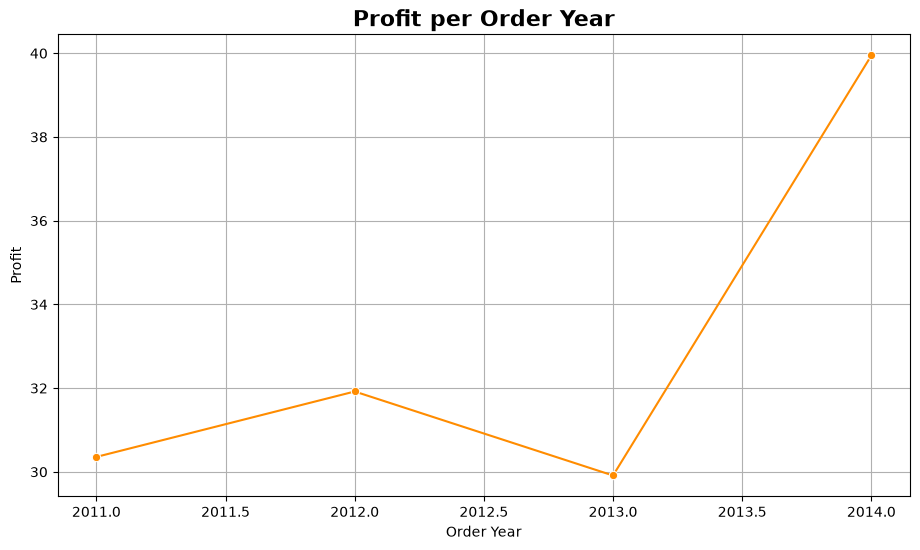

Profit,-3399.9800,-938.2800,-814.4832,-786.7440,-694.2936,-479.9880,-465.5680,-459.9875,-448.8960,-386.9570,...,942.8157,944.9865,1007.9832,1049.9850,1061.5722,1379.9770,1480.4671,1644.2913,1906.4850,6719.9808
Order_Year,,,,,,,,,,,,,,,,,,,,,
2011,NaN,NaN,NaN,NaN,2011.0,NaN,NaN,2011.0,NaN,NaN,...,NaN,NaN,NaN,NaN,2011.0,NaN,NaN,NaN,NaN,NaN
2012,NaN,NaN,NaN,2012.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,2012.0,NaN,NaN,NaN
2013,NaN,2013.0,2013.0,NaN,NaN,NaN,2013.0,NaN,NaN,2013.0,...,NaN,4026.0,NaN,NaN,NaN,NaN,NaN,2013.0,NaN,NaN
2014,2014.0,NaN,NaN,NaN,NaN,2014.0,NaN,NaN,2014.0,NaN,...,2014.0,NaN,2014.0,2014.0,NaN,2014.0,NaN,NaN,2014.0,2014.0


In [60]:
'''
Untuk pembuatan lineplot itu menggunakan kode sns.lineplot, dengan warna orange gelap dan grip sebagai garis penanda.
'''

# Membuat count plot
plt.figure(figsize=(11, 6))
sns.lineplot(x="Order_Year", y="Profit", data=df_copy, marker="o", color="darkorange", errorbar=None)
plt.title("Profit per Order Year", fontsize=16, fontweight="bold")
plt.xlabel("Order Year")
plt.grid(True)
plt.ylabel("Profit")
plt.show()

pd.crosstab(
    df_copy["Order_Year"],
    df_copy["Profit"],
    values=df_copy["Order_Year"],
    aggfunc="sum"
)

Dari tahun 2013 ke 2014, grafik menunjukkan garis yang sangat curam ke atas. Rata-rata profit per pesanan melonjak dari 30 menjadi 40.

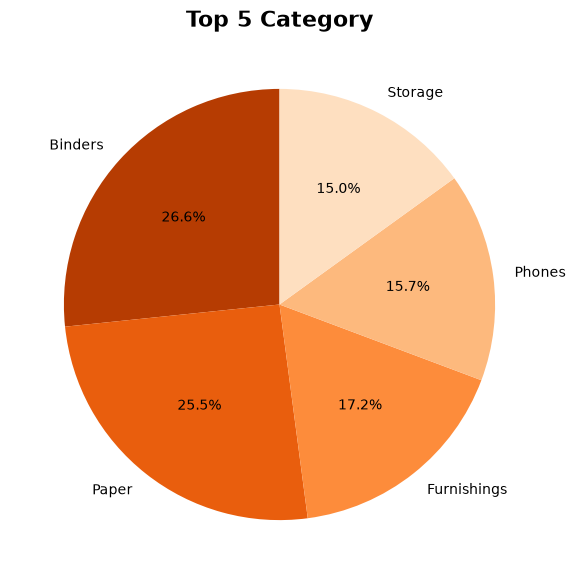

Category
Binders        471
Paper          450
Furnishings    304
Phones         277
Storage        266
Name: count, dtype: int64


In [61]:
'''
Untuk pembuatan Pie itu menggunakan kode plt.pie, dengan warna orange gelap dan grip sebagai garis penanda.
'''

# Membuat count plot
top_cat = df_copy["Category"].value_counts().head(5)

# Membuat warna menjadi berbagai macam warna orange
colors = sns.color_palette("Oranges", len(top_cat))[::-1]

# Membuat Pieplot
plt.figure(figsize=(12, 7))
plt.pie(
    top_cat,
    labels=top_cat.index,
    autopct="%1.1f%%",
    colors=colors,
    startangle=90)
plt.title("Top 5 Category", fontsize=16, fontweight="bold")
plt.show()

print(top_cat)

**Binder (26.6%)** Ini menunjukkan bahwa produk seperti Binder sangat sering dibeli oleh pelanggan (volume transaksi tinggi),
**Phones (15.7%) & Storage (15.0%)** Keduanya memiliki porsi yang hampir sama, sekitar 15% dari total transaksi.

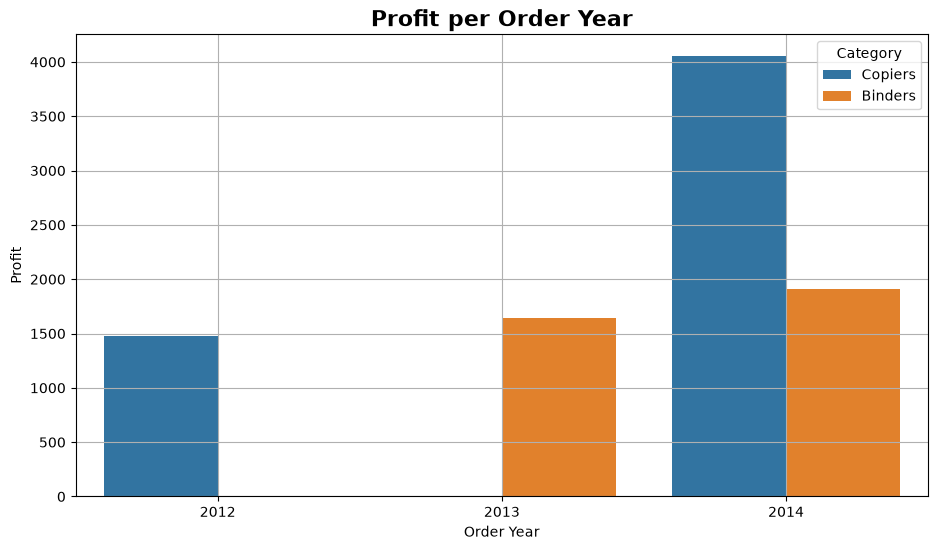

,Order_Year,Profit,Category
0,2014,6719.9808,Copiers
1,2014,1906.4850,Binders
2,2013,1644.2913,Binders
3,2012,1480.4671,Copiers
4,2014,1379.9770,Copiers


In [43]:
df_top5 = df_copy[["Order_Year", "Profit", "Category"]].nlargest(5, "Profit").reset_index(drop=True)

plt.figure(figsize=(11, 6))
sns.barplot(x="Order_Year", y="Profit", hue="Category", data=df_top5, errorbar=None)
plt.title("Profit per Order Year",fontsize=16, fontweight="bold")
plt.xlabel("Order Year")
plt.grid(True)
plt.ylabel("Profit")
plt.show()
df_top5

# Output Final Dataset

In [44]:
# Data Sebelum diubah
df

,Order ID,Order Date,Ship Date,EmailID,Geography,Category,Product Name,Sales,Quantity,Profit
0,CA-2013-138688,2013-06-13,2013-06-17,DarrinVanHuff@gmail.com,"United States,Los Angeles,California",Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,2,6.8714
1,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.860,7,14.1694
2,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Art,Newell 322,7.280,4,1.9656
3,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Phones,Mitel 5320 IP Phone VoIP phone,907.152,4,90.7152
4,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Binders,DXL Angle-View Binders with Locking Rings by S...,18.504,3,5.7825
...,...,...,...,...,...,...,...,...,...,...
3198,CA-2013-125794,2013-09-30,2013-10-04,MarisLaWare@gmail.com,"United States,Los Angeles,California",Accessories,Memorex Mini Travel Drive 64 GB USB 2.0 Flash ...,36.240,1,15.2208
3199,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2,15.6332
3200,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Phones,Aastra 57i VoIP phone,258.576,2,19.3932
3201,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4,13.3200


In [45]:
# Data Sesudah diubah
df_copy

,Order ID,Order Date,Ship Date,EmailID,Geography,Category,Product Name,Sales,Quantity,Profit,...,OrderID_Coder,OrderDate_Coder,ShipDate_Coder,EmailID_Coder,Geography_Coder,Category_Coder,ProductName_Coder,z_Score_Sales,z_Score_Quantity,z_Score_Profit
0,CA-2013-138688,2013-06-13,2013-06-17,DarrinVanHuff@gmail.com,"United States,Los Angeles,California",Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,2,6.8714,...,755,467,495,173,80,10,1164,-0.403726,-0.809040,-0.154971
1,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.860,7,14.1694,...,68,63,64,96,80,9,464,-0.338481,1.402768,-0.113048
2,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Art,Newell 322,7.280,4,1.9656,...,68,63,64,96,80,2,915,-0.417712,0.075683,-0.183152
3,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Phones,Mitel 5320 IP Phone VoIP phone,907.152,4,90.7152,...,68,63,64,96,80,13,884,1.296999,0.075683,0.326663
4,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Binders,DXL Angle-View Binders with Locking Rings by S...,18.504,3,5.7825,...,68,63,64,96,80,3,404,-0.396325,-0.366678,-0.161226
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3198,CA-2013-125794,2013-09-30,2013-10-04,MarisLaWare@gmail.com,"United States,Los Angeles,California",Accessories,Memorex Mini Travel Drive 64 GB USB 2.0 Flash ...,36.240,1,15.2208,...,692,535,576,433,80,0,870,-0.362529,-1.251401,-0.107008
3199,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2,15.6332,...,1062,637,683,174,31,9,1237,-0.256354,-0.809040,-0.104639
3200,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Phones,Aastra 57i VoIP phone,258.576,2,19.3932,...,1062,637,683,174,31,13,36,0.061134,-0.809040,-0.083040
3201,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4,13.3200,...,1062,637,683,174,31,12,754,-0.375181,0.075683,-0.117927


## Sampling

In [65]:
'''
Dalam kode sample() ini dapat digunakan untuk mengambil sample yang random pada data Amazon tersebut
'''
# Mengambil sample data
df_sample = df_copy.sample(n=10, random_state=42)
df_sample

,Order ID,Order Date,Ship Date,EmailID,Geography,Category,Product Name,Sales,Quantity,Profit,...,OrderID_Coder,OrderDate_Coder,ShipDate_Coder,EmailID_Coder,Geography_Coder,Category_Coder,ProductName_Coder,z_Score_Sales,z_Score_Quantity,z_Score_Profit
3008,CA-2014-102820,2014-05-08,2014-05-12,CarlosSoltero@gmail.com,"United States,Pasadena,California",Phones,Blue Parrot B250XT Professional Grade Wireless...,419.944,7,52.4930,...,949,681,728,109,104,13,281,0.368622,1.402768,0.107099
102,CA-2014-169901,2014-06-16,2014-06-20,ClayCheatham@gmail.com,"United States,San Francisco,California",Phones,Anker 36W 4-Port USB Wall Charger Travel Power...,47.976,3,4.7976,...,1372,706,754,145,134,13,127,-0.340166,-0.366678,-0.166884
862,CA-2011-153479,2011-10-04,2011-10-08,DavidFlashing@gmail.com,"United States,Vallejo,California",Binders,GBC Recycled Regency Composition Covers,95.648,2,31.0856,...,207,130,132,179,161,3,572,-0.249326,-0.809040,-0.015874
867,CA-2011-149244,2011-11-04,2011-11-08,MaryBethSkach@gmail.com,"United States,San Diego,California",Furnishings,"Executive Impressions 12"" Wall Clock",35.340,2,13.4292,...,195,150,155,438,133,9,498,-0.364244,-0.809040,-0.117300
999,CA-2011-104780,2011-05-21,2011-05-25,BradleyTalbott@gmail.com,"United States,San Diego,California",Art,4009 Highlighters by Sanford,31.840,8,10.5072,...,23,55,56,85,133,2,19,-0.370913,1.845130,-0.134085
1423,CA-2014-167003,2014-05-24,2014-05-30,VivekSundaresam@gmail.com,"United States,Los Angeles,California",Tables,"Lesro Sheffield Collection Coffee Table, End T...",171.288,3,-6.4233,...,1353,693,740,678,80,16,789,-0.105194,-0.366678,-0.231341
2956,CA-2014-140515,2014-03-20,2014-03-25,GeorgeZrebassa@gmail.com,"United States,Los Angeles,California",Appliances,Belkin 5 Outlet SurgeMaster Power Centers,381.360,7,106.7808,...,1199,650,696,259,80,1,242,0.295100,1.402768,0.418951
598,CA-2014-101245,2014-11-28,2014-12-04,LindsayWilliams@gmail.com,"United States,San Francisco,California",Paper,Tops White Computer Printout Paper,244.550,5,114.9385,...,934,817,883,406,134,12,1265,0.034407,0.518045,0.465812
170,CA-2013-136924,2013-07-15,2013-07-18,ErinSmith@gmail.com,"United States,Tucson,Arizona",Phones,LG Electronics Tone+ HBS-730 Bluetooth Headset,380.864,8,38.0864,...,744,487,517,232,158,13,781,0.294154,1.845130,0.024341
1720,CA-2014-158071,2014-06-11,2014-06-16,BillDonatelli@gmail.com,"United States,Seattle,Washington",Phones,Logitech B530 USBÂ HeadsetÂ -Â headsetÂ - Full...,88.776,3,7.7679,...,1299,702,753,74,145,13,800,-0.262421,-0.366678,-0.149821


## Laporan

Setelah saya analisi data Amazon jenis excel yang memiliki 3203 Baris dan 10 Kolom, tidak terdapa missing value, tidak ada data yang typo, dan tidak ada data yang duplicated. 

Tetapi di data amazon ada data yang memiliki outlier di bagaian Sales, Quantityada, dan Profit saat saya menggunakan kode boxplot(). Maka dari itu saya menggunakan zscore untuk mencari data yang memiliki outlier dengan menambahkan kolom tambahan yang saya buat. Seperti z_Score_Sales, z_Score_Quantity, dan z_Score_Profit untuk pendanda mana aja yang datanya outlier dengan cara mencari data yang lebih atau kurang dari 2.

Setelah mencari dan menemukan data outlier, saya mengatasinya dengan membiarkannya karena bisa jadi ada data yang salah input atau kostumernya berhutang.

Pada barplot disamping bisa disimpulkan bahwa **Copiers memiliki Jumlah total Profit sebesar 19327.24.** Setelah itu pada bagain **Bookcases Ini adalah "lubang" terbesar dalam laporan laba rugi kategori Kerugian di sini cukup signifikan sebesar -1.646,51.**

Pada Scatter Plot bisa disimpukan bahwa **Quantity (5) memiliki profit sekitar -3000 lebih,** ini adalah anomali karena barang tiba-tiba menyebabkan kerugian yang sangat besar. Setelah itu pada bagain **Quantity (4) memiliki profit sangat tinggi, mencapai sekitar +6500 lebih.** Ini juga anomali karena menghasilkan keuntungan yang jauh lebih besar

Tahun 2013 ke 2014, grafik menunjukkan garis yang sangat curam ke atas. Rata-rata profit per pesanan melonjak dari 30 menjadi 40.